# Recuperación densa SciBERT Top-3 vs BM25 (issue #102)

## 1. Alcance y aviso

Este notebook **solo lee la evidencia versionada** en `proyecto_de_grado/docs/evidencias_recuperacion_densa_a1/` (sin torch, sin GPU).

> **Esto NO es una evaluación de relevancia.** Los contextos son de *train* y **no hay gold validado de chunks** (pendiente en el issue #127).
> No se calcula Recall@3, Hit@3 ni MRR@3. Lo que se mide es el **acuerdo** entre SciBERT y BM25, y propiedades técnicas (distribución por sección, similitud, latencia, determinismo).
> Ningún resultado de aquí permite afirmar que un método sea mejor que el otro.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "proyecto_de_grado").is_dir())
E = RAIZ / "proyecto_de_grado/docs/evidencias_recuperacion_densa_a1"
resumen = json.loads((E / "resumen.json").read_text())
lat = json.loads((E / "latencias_resumen.json").read_text())
extra = json.loads((E / "cpu_vs_cuda_60.json").read_text())
manif = json.loads((E / "manifiesto.json").read_text())
cmp_ = pd.read_csv(E / "comparacion.csv")
top3 = pd.read_csv(E / "top3.csv")
div = pd.read_csv(E / "diversidad.csv")

# Paleta categorica validada (slots 1-2 de la paleta de referencia) + gris neutro para el corpus.
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "text.color": INK, "axes.grid": True, "grid.color": "#e5e4e0",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})
print("modelo:", resumen["modelo"]["model_id"], "@", resumen["modelo"]["revision"][:12])
print("estado:", resumen["estado"], "|", resumen["metricas_relevancia"])
print("commit de la corrida:", manif["git"]["head"][:12], "| arbol sucio:", manif["git"]["dirty"])

modelo: allenai/scibert_scivocab_uncased @ 24f92d32b1bf
estado: comparacion_tecnica_train_sin_gold | no calculadas: sin gold validado
commit de la corrida: ca4cc5bbc148 | arbol sucio: True


## 2. Sesgo de contextos por artículo

Hay 605 contextos de train sobre 91 artículos citados, muy concentrados. Por eso toda cifra se da **micro** (por contexto) y **macro** (promedio de promedios por artículo).

contextos: 605 | artículos: 91 | mediana por artículo: 2 | artículos con 1 contexto: 31
top 5: {'P98-1013': 107, 'P97-1023': 68, 'E06-1015': 46, 'P09-1116': 31, 'N06-1058': 30}


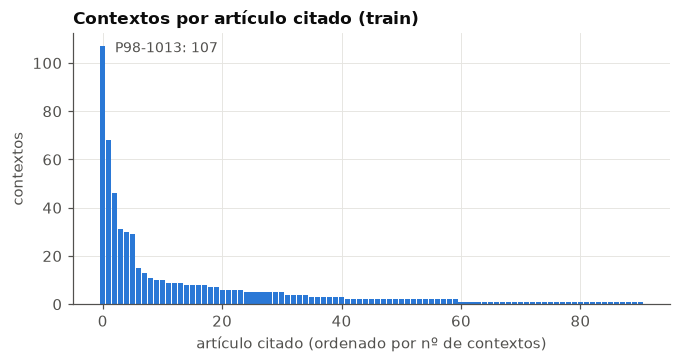

In [2]:
por_art = cmp_.groupby("cited_id").size().sort_values(ascending=False)
print(f"contextos: {len(cmp_)} | artículos: {por_art.size} | mediana por artículo: {por_art.median():.0f} | "
      f"artículos con 1 contexto: {(por_art == 1).sum()}")
print("top 5:", por_art.head(5).to_dict())
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(len(por_art)), por_art.values, color=AZUL, width=0.85)
ax.set_xlabel("artículo citado (ordenado por nº de contextos)")
ax.set_ylabel("contextos")
ax.set_title("Contextos por artículo citado (train)")
ax.annotate(f"{por_art.index[0]}: {por_art.iloc[0]}", (0, por_art.iloc[0]), xytext=(8, -4),
            textcoords="offset points", color=INK2, fontsize=9)
plt.show()

## 3. Solape vs azar, Top-1 y abstenciones

*Solape@3* = (chunks en común entre los Top-3 de SciBERT y BM25) / 3. El valor esperado por azar con `n` chunks es `k²/n` (k = 3). **Mide acuerdo, no relevancia.**

,n,solape@3,azar (solape@3),Jaccard,mismo Top-1,BM25 sin resultados
nivel,,,,,,
micro,605,0.272,0.112,0.184,0.193,0.0
macro,91,0.306,0.128,0.212,0.228,0.0


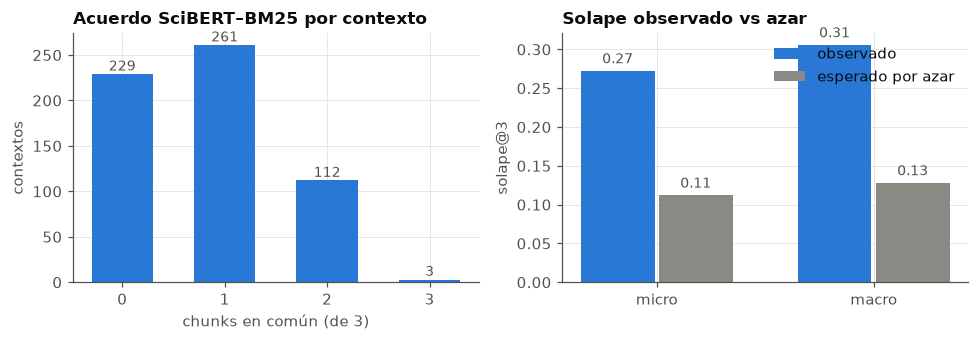

micro sin P98-1013 (498 contextos): solape@3 = 0.280


In [3]:
filas = []
for nivel in ("micro", "macro"):
    r = resumen["comparacion"][nivel]
    filas.append({"nivel": nivel, "n": r["n"], "solape@3": r["solape_3"], "azar (solape@3)": r["solape_esperado_azar"],
                  "Jaccard": r["jaccard"], "mismo Top-1": r["mismo_top1"], "BM25 sin resultados": r["abstencion_bm25"]})
display(pd.DataFrame(filas).round(3).set_index("nivel"))

dist = cmp_["interseccion"].value_counts().reindex([0, 1, 2, 3], fill_value=0)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
axs[0].bar(dist.index.astype(str), dist.values, color=AZUL, width=0.6)
for x, v in zip(dist.index.astype(str), dist.values):
    axs[0].text(x, v + 4, f"{v}", ha="center", fontsize=9, color=INK2)
axs[0].set(xlabel="chunks en común (de 3)", ylabel="contextos", title="Acuerdo SciBERT–BM25 por contexto")
niv = ["micro", "macro"]
obs = [resumen["comparacion"][n]["solape_3"] for n in niv]
azar = [resumen["comparacion"][n]["solape_esperado_azar"] for n in niv]
x = np.arange(2)
axs[1].bar(x - 0.18, obs, 0.34, color=AZUL, label="observado")
axs[1].bar(x + 0.18, azar, 0.34, color=GRIS, label="esperado por azar")
for xi, v in zip(x - 0.18, obs): axs[1].text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=9, color=INK2)
for xi, v in zip(x + 0.18, azar): axs[1].text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=9, color=INK2)
axs[1].set_xticks(x, niv); axs[1].set(ylabel="solape@3", title="Solape observado vs azar"); axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()

sin = cmp_[cmp_["cited_id"] != "P98-1013"]
print(f"micro sin P98-1013 ({len(sin)} contextos): solape@3 = {sin['interseccion'].mean() / 3:.3f}")

## 4. Secciones: corpus vs SciBERT vs BM25

El perfil de sección es una **heurística por palabras clave no validada**; ~50 % del corpus cae en «otra». Se muestra solo para ver si algún método se desvía del corpus.

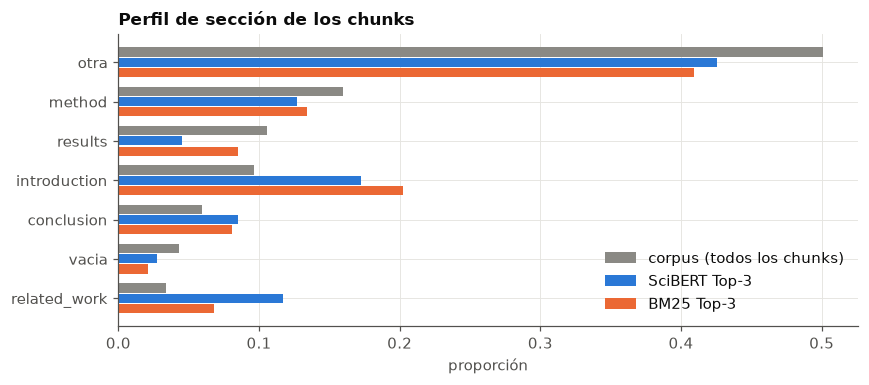

,corpus,denso,bm25
perfil (%),,,
otra,50.1,42.5,40.9
method,16.0,12.7,13.4
results,10.6,4.5,8.5
introduction,9.7,17.2,20.2
conclusion,6.0,8.5,8.1
vacia,4.3,2.8,2.1
related_work,3.4,11.7,6.8


In [4]:
sec = pd.DataFrame(resumen["secciones"])[["corpus", "denso", "bm25"]]
orden = sec["corpus"].sort_values(ascending=False).index
sec = sec.loc[orden]
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(sec)); h = 0.26
for i, (col, color, lab) in enumerate([("corpus", GRIS, "corpus (todos los chunks)"), ("denso", AZUL, "SciBERT Top-3"), ("bm25", NARANJA, "BM25 Top-3")]):
    ax.barh(y + (i - 1) * h, sec[col], h * 0.9, color=color, label=lab)
ax.set_yticks(y, sec.index); ax.invert_yaxis(); ax.set(xlabel="proporción", title="Perfil de sección de los chunks")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
display((sec * 100).round(1).rename_axis("perfil (%)"))

## 5. Similitudes y hubness

El coseno de SciBERT con *mean pooling* sin ajuste de recuperación es **anisotrópico**: todos los chunks de un artículo se parecen mucho a cualquier consulta. Dos indicadores: el nivel del coseno Top-1 y qué tan repetido es un mismo chunk como Top-1 entre los contextos de un artículo (hubness).

coseno Top-1: media 0.903 (min 0.732, max 0.944)
brecha Top-1 – Top-2: media 0.0078 (max 0.0513)
artículos con >=2 contextos: 60 | cobertura media de chunks distintos en Top-3: 0.30 | fracción de contextos que comparten el Top-1 más frecuente: 0.50


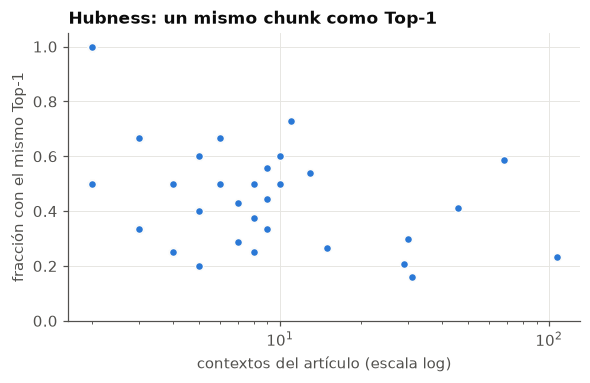

In [5]:
s = resumen["similitud"]
print(f"coseno Top-1: media {s['top1']['media']:.3f} (min {s['top1']['min']:.3f}, max {s['top1']['max']:.3f})")
print(f"brecha Top-1 – Top-2: media {s['brecha_top1_top2']['media']:.4f} (max {s['brecha_top1_top2']['max']:.4f})")
d = resumen["diversidad"]
print(f"artículos con >=2 contextos: {d['articulos_con_2_o_mas_contextos']} | cobertura media de chunks distintos en Top-3: "
      f"{d['cobertura_media']:.2f} | fracción de contextos que comparten el Top-1 más frecuente: {d['top1_mas_frecuente_medio']:.2f}")
m = div[div["contextos"] >= 2]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(m["contextos"], m["chunk_top1_mas_frecuente"], s=28, color=AZUL, edgecolor="#fcfcfb", linewidth=1)
ax.set(xscale="log", xlabel="contextos del artículo (escala log)", ylabel="fracción con el mismo Top-1",
       title="Hubness: un mismo chunk como Top-1", ylim=(0, 1.05))
plt.show()

## 6. Latencias

Una sola GPU (RTX 4070 SUPER) y una CPU de escritorio: **no es la latencia de la API**. BM25 incluye indexar los chunks del artículo en cada consulta. El embedding por artículo se paga una vez por artículo (con caché, ~0).

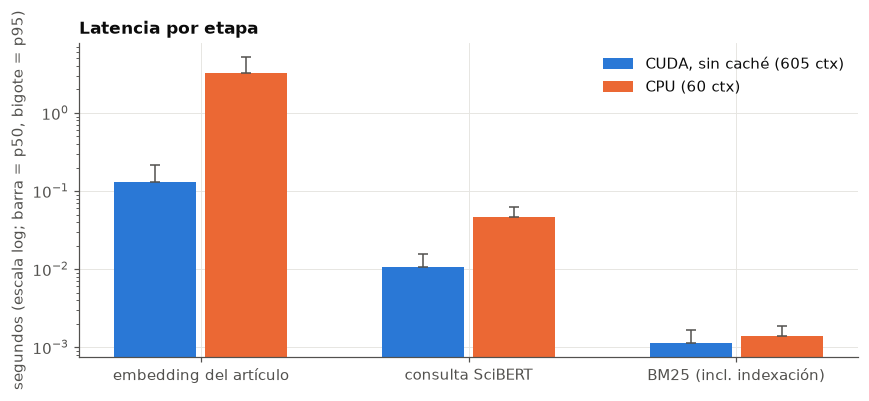

,corrida_cuda_1,cpu_60
embedding_articulo p50/p95 (s),0.1311 / 0.2125,3.2578 / 5.1740
consulta_densa p50/p95 (s),0.0107 / 0.0156,0.0460 / 0.0623
bm25 p50/p95 (s),0.0011 / 0.0017,0.0014 / 0.0019
carga del modelo (s),1.40,1.13
memoria GPU máx. (MB),689,—


In [6]:
L = extra["latencias_s"]
etapas = [("embedding_articulo", "embedding del artículo"), ("consulta_densa", "consulta SciBERT"), ("bm25", "BM25 (incl. indexación)")]
corridas = [("corrida_cuda_1", "CUDA, sin caché (605 ctx)", AZUL), ("cpu_60", "CPU (60 ctx)", NARANJA)]
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(etapas)); w = 0.34
for i, (k, lab, color) in enumerate(corridas):
    p50 = [L[k][e]["p50"] for e, _ in etapas]; p95 = [L[k][e]["p95"] for e, _ in etapas]
    ax.bar(x + (i - 0.5) * w, p50, w * 0.9, color=color, label=lab)
    ax.errorbar(x + (i - 0.5) * w, p50, yerr=[np.zeros(3), np.array(p95) - np.array(p50)], fmt="none", ecolor=INK2, capsize=3, lw=1)
ax.set_yscale("log"); ax.set_xticks(x, [n for _, n in etapas]); ax.set(ylabel="segundos (escala log; barra = p50, bigote = p95)", title="Latencia por etapa")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
tab = pd.DataFrame({k: {f"{e} p50/p95 (s)": f"{L[k][e]['p50']:.4f} / {L[k][e]['p95']:.4f}" for e, _ in etapas} for k, *_ in corridas})
tab.loc["carga del modelo (s)"] = [f"{L[k]['carga_modelo_s']:.2f}" for k, *_ in corridas]
tab.loc["memoria GPU máx. (MB)"] = [("—" if L[k]["memoria_gpu_max_mb"] is None else f"{L[k]['memoria_gpu_max_mb']:.0f}") for k, *_ in corridas]
display(tab)

## 7. Integridad y determinismo

- **Integridad:** cada par `(cited_id, chunk_id)` devuelto pertenece al artículo del caso, con sección e índices coincidentes con el corpus, sin duplicados y ≤3 resultados, para SciBERT **y** BM25. Si hubiera una violación, la corrida aborta sin escribir nada.
- **Determinismo:** corrida CUDA 1 (`--sin-cache`) vs corrida CUDA 2 (con caché), y CPU vs CUDA sobre 60 contextos.

In [7]:
print("violaciones de integridad:", resumen["integridad"]["violaciones"], "| métodos:", resumen["integridad"]["metodos"])
print("CUDA 1 vs CUDA 2 -> resumen.json idéntico:", extra["cuda1_vs_cuda2"]["resumen_json_identico"],
      "| top3.csv idéntico:", extra["cuda1_vs_cuda2"]["top3_csv_identico"])
c = extra["cpu_vs_cuda"]
print(f"CPU vs CUDA ({c['contextos']} contextos): mismo orden Top-3 {c['mismo_orden_top3']}/{c['contextos']}, "
      f"mismo conjunto {c['mismo_conjunto_top3']}/{c['contextos']}, mismo Top-1 {c['mismo_top1']}/{c['contextos']}, "
      f"máx. diferencia de coseno {c['max_dif_coseno_abs']:.1e}")
assert resumen["integridad"]["violaciones"] == 0

violaciones de integridad: 0 | métodos: ['scibert', 'bm25']
CUDA 1 vs CUDA 2 -> resumen.json idéntico: True | top3.csv idéntico: True
CPU vs CUDA (60 contextos): mismo orden Top-3 60/60, mismo conjunto 60/60, mismo Top-1 60/60, máx. diferencia de coseno 1.0e-06


## 8. Ejemplos Top-3

Muestra estratificada por nivel de acuerdo (semilla 102, extractos ≤240 caracteres). **No indica cuál es correcto.**

In [8]:
txt = (E / "ejemplos_top3.md").read_text()
bloques = txt.split("\n## ")[1:]
display(Markdown("## " + "\n\n## ".join(bloques[:3])))
print(f"({len(bloques)} ejemplos en ejemplos_top3.md)")

## D13-1018_P10-1029_0 (P10-1029) — coinciden 0/3

> 6) have been successfully applied to several tasks, including learning semantic relations ( ), extracting surface text patterns for open-domain question answering ( ), semantic tagging ( and unsupervised Word Sense Disambiguation ( ). ProT…

**denso**
1. `p00031-p00032` (Dynamic Semantic Features): For many NLP tasks, classifiers use semantic features to represent the semantic class of words. These features are typically obtained from external resources such as Wordnet (Miller, 1990 ). Our bootstrapping model incrementally trains sem…
2. `p00054-p00054` (Conclusions): We presented a novel technique for inducing domain-specific semantic class taggers from a handful of seed words and an unannotated text collection. Our results showed that the induced taggers achieve good performance on six semantic catego…
3. `p00006-p00006` (Introduction): We evaluate our approach by creating six semantic taggers using a collection of message board posts in the domain of veterinary medicine. Our results show this approach produces high-quality semantic taggers after a sustained bootstrapping…

**bm25**
1. `p00000-p00001` (Introduction): The goal of our research is to create semantic class taggers that can assign a semantic class label to every noun phrase in a sentence. For example, consider the sentence: "The lab mix was diagnosed with parvo and given abx". A semantic ta…
2. `p00009-p00009` (Related Work): There has also been work on extracting semantically related terms or category members from the Web (e.g., (Paşca, 2004; Etzioni et al., 2005; Kozareva et al., 2008; Carlson et al., 2009) ). These techniques harvest broad-coverage semantic…
3. `p00002-p00003` (Introduction): Despite widespread interest in semantic tagging, nearly all semantic taggers for comprehensive NP tagging still rely on supervised learning, which requires annotated data for training. A few annotated corpora exist, but they are relatively…


## N13-1008_D11-1135_2 (D11-1135) — coinciden 1/3

> by working with the BPR objective, and by more extensive experiments. Relational Clustering There is a large body of work aiming to discover latent relations by clustering surface patterns ( ; ; ), or by inducing synonymy relationships bet…

**denso**
1. `p00001-p00001` (Introduction): Past work has shown that standard supervised techniques can yield high-performance relation detection when abundant labeled data exists for a fixed inventory of individual relation types (e.g. leaderOf ) (Kambhatla, 2004; Culotta and Soren…
2. `p00047-p00048` (Related Work): Relation duality (Bollegala et al., 2010) employs co-clustering to find clusters of entity pairs and patterns. They identify each cluster of entity pairs as a relation by selecting representative patterns for that relation. This approach i…
3. `p00045-p00046` (Related Work): For example, DIRT (Lin and Pantel, 2001 ) aims to discover different representations of the same semantic relation, i.e. similar dependency paths. They employ the distributional similarity based approach while we use generative models. Bot…

**bm25**
1. `p00003-p00003` (Problem and Experimental Setup): The task of relation extraction is mapping surface textual relations to underlying semantic relations. For instance, the textual expression "X was born in Y" indicates a semantic relation bornIn between entities "X" and "Y". This relation…
2. `p00043-p00044` (Related Work): Distant supervision for relation extraction requires no labeled data. The approach takes some existing knowledge base as supervision source, matches its relational instances against the text corpus to build the training data, and extracts…
3. `p00001-p00001` (Introduction): Past work has shown that standard supervised techniques can yield high-performance relation detection when abundant labeled data exists for a fixed inventory of individual relation types (e.g. leaderOf ) (Kambhatla, 2004; Culotta and Soren…


## W12-3201_P84-1008_0 (P84-1008) — coinciden 2/3

> ntactic considerations only. 1983 proposed the centering model which is concerned with the interactions between the local coherence of discourse and the choices of referring expressions. 1984 provides examples of feature structures in whic…

**denso**
1. `p00023-p00024` (Limitations of Some Current Formalisms): -er = Fnumber: pl l [_case' ~atJJ The second alternative seems preferrable given the fact that there is, in this particular declension, a clear twoway contrast. The marked dative is in opposition with an unmarked form representing all the…
2. `p00019-p00020` (Limitations of Some Current Formalisms): Not allowing disjunctive specifications rules out matrices of the following sort. We indicate disjunction by enclosing the alternative values in {}. The first line describes the value of case as being "either nominative or accusative." The…
3. `p00008-p00008` (Introduction): In a ca~'~e like this, the values of the two paths have been "unified." To represent unification in terms of feature matrices we need to introduce some new convention to distinguish between identity and mere likeness. Even that would not q…

**bm25**
1. `p00041-p00042` ((A -C) n (B -D) = (A n B) -(C u D)): In our current implementation, negative constraints are dropped as soon as they become redundant as far as unification is concerned. For example, when [case: ace] is unified with with [case: -dat], the resulting matrix is simply [case: acc…
2. `p00019-p00020` (Limitations of Some Current Formalisms): Not allowing disjunctive specifications rules out matrices of the following sort. We indicate disjunction by enclosing the alternative values in {}. The first line describes the value of case as being "either nominative or accusative." The…
3. `p00008-p00008` (Introduction): In a ca~'~e like this, the values of the two paths have been "unified." To represent unification in terms of feature matrices we need to introduce some new convention to distinguish between identity and mere likeness. Even that would not q…


(12 ejemplos en ejemplos_top3.md)


## 9. Limitaciones

- **Sin gold:** no hay Recall/Hit/MRR; el solape mide acuerdo entre dos métodos, no relevancia (gold pendiente: issue #127).
- Solo **train** y la caché local de 200 artículos; el 37 % de los artículos descargados se descarta en la extracción (A1, #101).
- Contextos **muy concentrados** (P98-1013 aporta 107 de 605): por eso se reporta macro además de micro.
- SciBERT con *mean pooling* **no es un recuperador entrenado** (anisotropía: coseno Top-1 ≈ 0,90 y brecha Top-1–Top-2 ≈ 0,008).
- La heurística de sección **no está validada** y ~50 % cae en «otra»; el 4,3 % de los chunks no tiene sección.
- Los párrafos `EQUATION` cortan oraciones y las **ventanas de 512 tokens** cortan por frontera de ventana.
- Latencia medida en **una sola GPU** y una CPU de escritorio, no en la API; BM25 incluye la indexación.
- La corrida se hizo con el árbol de trabajo **sucio** respecto al commit registrado en el manifiesto (ver §1).